# 🕵️ Fake Review Detection — Full Pipeline
**Two models, one notebook:**
1. **Fraud Detector** — trained on `fake_reviews_dataset.csv` (labeled CG/OR) → detects fake vs genuine reviews
2. **Sentiment Analyzer** — trained on `all_kindle_review_.csv` (star ratings) → predicts positive / neutral / negative

**Combined output:** suspicion score + sentiment + rating-sentiment mismatch — ready to plug into a web app.

---
### 📁 Required files (upload to Colab before running)
- `fake_reviews_dataset.csv`
- `all_kindle_review_.csv`


## 0. Install dependencies

In [3]:
%pip install -q xgboost scikit-learn pandas numpy joblib matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## 1. Imports & config

In [4]:
import os, warnings
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, roc_auc_score, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
os.makedirs("./fake_review_detector", exist_ok=True)

SEED       = 42
OUTPUT_DIR = "./fake_review_detector"
print("✓ Imports done")


✓ Imports done


---
## 3. Fraud Detection Model
### 3.1 Load & explore `fake_reviews_dataset.csv`

In [5]:
fraud_df = pd.read_csv("fake_reviews_dataset.csv").dropna(subset=["text_", "label"])
fraud_df["label_id"] = (fraud_df["label"] == "CG").astype(int)  # OR=0 genuine, CG=1 fake

print(f"Shape       : {fraud_df.shape}")
print(f"Label split :\n{fraud_df['label'].value_counts()}")
print(f"Nulls       :\n{fraud_df.isnull().sum()}")
print(f"\nSample reviews:")
display(fraud_df[["label","rating","text_"]].sample(4, random_state=1))


Shape       : (40432, 5)
Label split :
label
CG    20216
OR    20216
Name: count, dtype: int64
Nulls       :
category    0
rating      0
label       0
text_       0
label_id    0
dtype: int64

Sample reviews:


,label,rating,text_
17796,CG,5.0,Excellent value. Easy to use. Buy it.works g...
25778,OR,5.0,I really enjoyed this book. It was surprising...
10524,CG,3.0,"I loved this at first, but it didn't last. I d..."
36860,CG,1.0,"Did not like the fit, it was too long. I will ..."


### 3.2 Exploratory Data Analysis

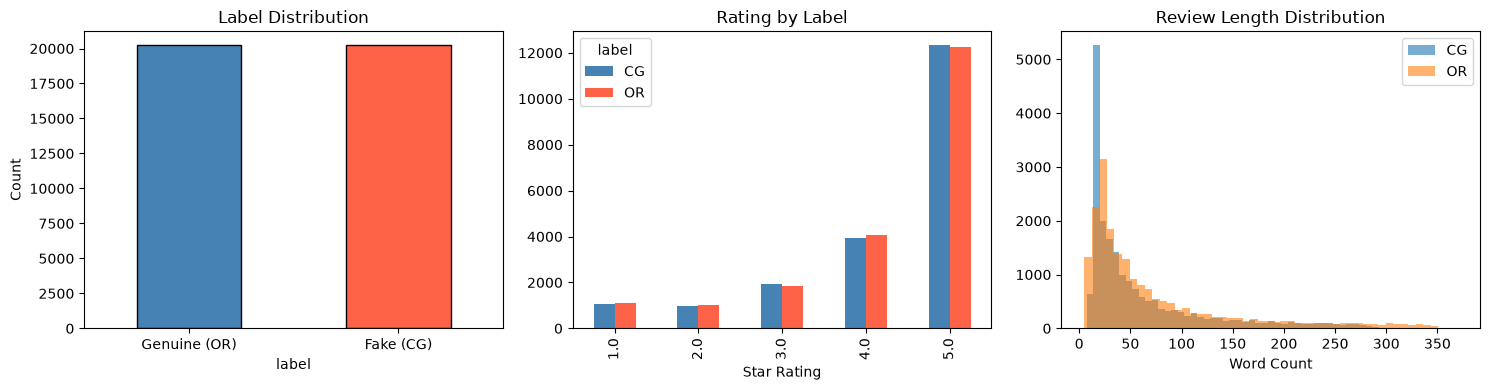

Avg word count — OR: 74 | CG: 61


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Label distribution
fraud_df["label"].value_counts().plot(kind="bar", ax=axes[0], color=["steelblue","tomato"], edgecolor="black")
axes[0].set_title("Label Distribution")
axes[0].set_xticklabels(["Genuine (OR)", "Fake (CG)"], rotation=0)
axes[0].set_ylabel("Count")

# Rating distribution by label
fraud_df.groupby(["rating","label"]).size().unstack().plot(kind="bar", ax=axes[1], color=["steelblue","tomato"])
axes[1].set_title("Rating by Label")
axes[1].set_xlabel("Star Rating")

# Text length distribution
fraud_df["text_len"] = fraud_df["text_"].str.split().apply(len)
for lbl, grp in fraud_df.groupby("label"):
    axes[2].hist(grp["text_len"], bins=50, alpha=0.6, label=lbl)
axes[2].set_title("Review Length Distribution")
axes[2].set_xlabel("Word Count")
axes[2].legend()

plt.tight_layout()
plt.show()
print(f"Avg word count — OR: {fraud_df[fraud_df.label=='OR']['text_len'].mean():.0f} | CG: {fraud_df[fraud_df.label=='CG']['text_len'].mean():.0f}")


### 3.3 Preprocess & train TF-IDF + XGBoost

In [7]:
# Prepend rating as extra signal
fraud_df["text_with_rating"] = fraud_df["rating"].astype(str) + " stars. " + fraud_df["text_"]

X = fraud_df["text_with_rating"]
y = fraud_df["label_id"]

# 80 / 10 / 10 split
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
X_val,   X_test, y_val,   y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# TF-IDF
print("\nFitting TF-IDF...")
fraud_tfidf = TfidfVectorizer(max_features=50_000, ngram_range=(1,2), sublinear_tf=True, min_df=2)
X_train_vec = fraud_tfidf.fit_transform(X_train)
X_val_vec   = fraud_tfidf.transform(X_val)
X_test_vec  = fraud_tfidf.transform(X_test)
print(f"Vocabulary size: {len(fraud_tfidf.vocabulary_):,}")

# XGBoost
print("\nTraining XGBoost fraud model...")
fraud_model = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric="logloss", random_state=SEED,
    n_jobs=-1, tree_method="hist"
)
fraud_model.fit(X_train_vec, y_train, eval_set=[(X_val_vec, y_val)], verbose=50)
print("\n✓ Fraud model trained")


Train: 32345 | Val: 4043 | Test: 4044

Fitting TF-IDF...
Vocabulary size: 50,000

Training XGBoost fraud model...
[0]	validation_0-logloss:0.66871
[50]	validation_0-logloss:0.37914
[100]	validation_0-logloss:0.31763
[150]	validation_0-logloss:0.28615
[200]	validation_0-logloss:0.26491
[250]	validation_0-logloss:0.24952
[299]	validation_0-logloss:0.23850

✓ Fraud model trained


### 3.4 Evaluate fraud model

=== Fraud Detection — Test Set Results ===
Accuracy : 0.9164
ROC-AUC  : 0.9764

              precision    recall  f1-score   support

Genuine (OR)       0.90      0.93      0.92      2022
   Fake (CG)       0.93      0.90      0.92      2022

    accuracy                           0.92      4044
   macro avg       0.92      0.92      0.92      4044
weighted avg       0.92      0.92      0.92      4044



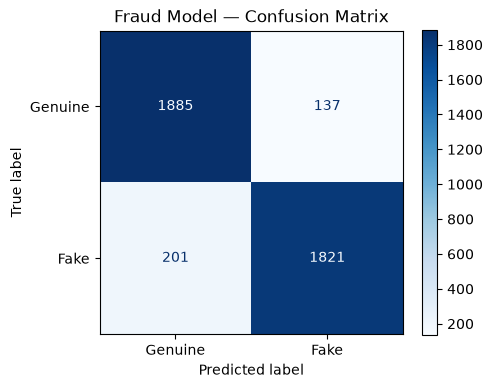

In [8]:
y_pred      = fraud_model.predict(X_test_vec)
y_pred_prob = fraud_model.predict_proba(X_test_vec)[:, 1]

print("=== Fraud Detection — Test Set Results ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_pred_prob):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=["Genuine (OR)", "Fake (CG)"]))

# Confusion matrix
fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Genuine","Fake"]).plot(ax=ax, cmap="Blues")
ax.set_title("Fraud Model — Confusion Matrix")
plt.tight_layout()
plt.show()


### 3.5 Save fraud model

In [9]:
joblib.dump(fraud_tfidf, f"{OUTPUT_DIR}/tfidf.pkl")
joblib.dump(fraud_model, f"{OUTPUT_DIR}/xgb_model.pkl")
print(f"✓ Saved tfidf.pkl and xgb_model.pkl → {OUTPUT_DIR}/")


✓ Saved tfidf.pkl and xgb_model.pkl → ./fake_review_detector/


---
## 4. Sentiment Analysis Model
### 4.1 Load & explore `all_kindle_review_.csv`

In [12]:
kindle_df = pd.read_csv("all_kindle_review.csv")
kindle_df = kindle_df[["rating","reviewText","summary"]].dropna(subset=["reviewText","rating"]).reset_index(drop=True)
kindle_df["summary"] = kindle_df["summary"].fillna("")

print(f"Shape  : {kindle_df.shape}")
print(f"Rating distribution:\n{kindle_df['rating'].value_counts().sort_index()}")
print()
display(kindle_df[["rating","reviewText","summary"]].sample(3, random_state=1))


Shape  : (12000, 3)
Rating distribution:
rating
1    2000
2    2000
3    2000
4    3000
5    3000
Name: count, dtype: int64



,rating,reviewText,summary
7163,4,Federal Judge Jackson Benedict is trying a cas...,Court Appointed
10385,1,This book didn't interest me at all... I felt ...,Thumbs down
1902,4,Novella length urban fantasy along the lines o...,Nifty little urban fantasy taster...


### 4.2 Exploratory Data Analysis

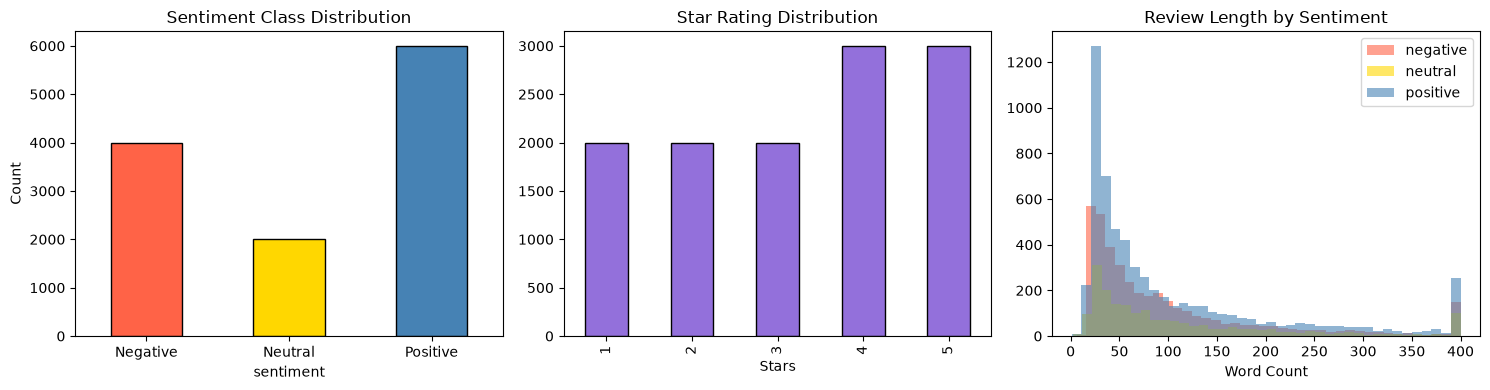

Avg length — negative: 106 words | positive: 108 words


In [13]:
# Bucket ratings → sentiment labels
def to_sentiment(r):
    if r <= 2: return "negative"
    if r == 3: return "neutral"
    return "positive"

SENT_MAP  = {"negative": 0, "neutral": 1, "positive": 2}
kindle_df["sentiment"]    = kindle_df["rating"].apply(to_sentiment)
kindle_df["sentiment_id"] = kindle_df["sentiment"].map(SENT_MAP)
kindle_df["text_len"]     = kindle_df["reviewText"].str.split().apply(len)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Sentiment distribution
colors = ["tomato","gold","steelblue"]
kindle_df["sentiment"].value_counts().reindex(["negative","neutral","positive"]).plot(
    kind="bar", ax=axes[0], color=colors, edgecolor="black"
)
axes[0].set_title("Sentiment Class Distribution")
axes[0].set_xticklabels(["Negative","Neutral","Positive"], rotation=0)
axes[0].set_ylabel("Count")

# Rating distribution
kindle_df["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="mediumpurple", edgecolor="black")
axes[1].set_title("Star Rating Distribution")
axes[1].set_xlabel("Stars")

# Text length by sentiment
for sent, color in zip(["negative","neutral","positive"], colors):
    grp = kindle_df[kindle_df.sentiment == sent]
    axes[2].hist(grp["text_len"].clip(0, 400), bins=40, alpha=0.6, label=sent, color=color)
axes[2].set_title("Review Length by Sentiment")
axes[2].set_xlabel("Word Count")
axes[2].legend()

plt.tight_layout()
plt.show()
print(f"Avg length — negative: {kindle_df[kindle_df.sentiment=='negative']['text_len'].mean():.0f} words | positive: {kindle_df[kindle_df.sentiment=='positive']['text_len'].mean():.0f} words")


### 4.3 Train TF-IDF + XGBoost sentiment model

In [14]:
# Combine reviewText + summary
kindle_df["full_text"] = kindle_df["reviewText"] + " " + kindle_df["summary"]

X_s = kindle_df["full_text"]
y_s = kindle_df["sentiment_id"]

X_tr_s, X_tmp_s, y_tr_s, y_tmp_s = train_test_split(X_s, y_s, test_size=0.2, random_state=SEED, stratify=y_s)
X_vl_s, X_te_s, y_vl_s, y_te_s  = train_test_split(X_tmp_s, y_tmp_s, test_size=0.5, random_state=SEED, stratify=y_tmp_s)
print(f"Train: {len(X_tr_s)} | Val: {len(X_vl_s)} | Test: {len(X_te_s)}")

print("\nFitting TF-IDF (sentiment)...")
sent_tfidf = TfidfVectorizer(max_features=40_000, ngram_range=(1,2), sublinear_tf=True, min_df=2)
X_tr_s_vec = sent_tfidf.fit_transform(X_tr_s)
X_vl_s_vec = sent_tfidf.transform(X_vl_s)
X_te_s_vec = sent_tfidf.transform(X_te_s)

print("Training XGBoost sentiment model...")
sent_model = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    objective="multi:softprob", num_class=3,
    eval_metric="mlogloss", random_state=SEED,
    n_jobs=-1, tree_method="hist"
)
sent_model.fit(X_tr_s_vec, y_tr_s, eval_set=[(X_vl_s_vec, y_vl_s)], verbose=50)
print("\n✓ Sentiment model trained")


Train: 9600 | Val: 1200 | Test: 1200

Fitting TF-IDF (sentiment)...
Training XGBoost sentiment model...
[0]	validation_0-mlogloss:0.99200
[50]	validation_0-mlogloss:0.71206
[100]	validation_0-mlogloss:0.64620
[150]	validation_0-mlogloss:0.61476
[200]	validation_0-mlogloss:0.59731
[250]	validation_0-mlogloss:0.58525
[299]	validation_0-mlogloss:0.57965

✓ Sentiment model trained


### 4.4 Evaluate sentiment model

=== Sentiment Analysis — Test Set Results ===
Accuracy : 0.7583

              precision    recall  f1-score   support

    Negative       0.77      0.81      0.79       400
     Neutral       0.47      0.20      0.28       200
    Positive       0.79      0.91      0.84       600

    accuracy                           0.76      1200
   macro avg       0.67      0.64      0.64      1200
weighted avg       0.73      0.76      0.73      1200



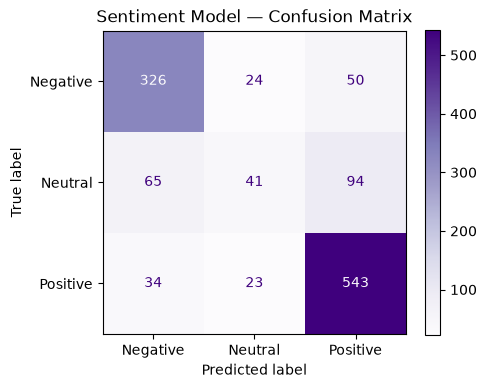

In [15]:
y_pred_s = sent_model.predict(X_te_s_vec)

print("=== Sentiment Analysis — Test Set Results ===")
print(f"Accuracy : {accuracy_score(y_te_s, y_pred_s):.4f}")
print()
print(classification_report(y_te_s, y_pred_s, target_names=["Negative","Neutral","Positive"]))

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(confusion_matrix(y_te_s, y_pred_s), display_labels=["Negative","Neutral","Positive"]).plot(ax=ax, cmap="Purples")
ax.set_title("Sentiment Model — Confusion Matrix")
plt.tight_layout()
plt.show()


### 4.5 Save sentiment model

In [16]:
joblib.dump(sent_tfidf, f"{OUTPUT_DIR}/tfidf_sentiment.pkl")
joblib.dump(sent_model, f"{OUTPUT_DIR}/sentiment_model.pkl")
print(f"✓ Saved tfidf_sentiment.pkl and sentiment_model.pkl → {OUTPUT_DIR}/")
print(f"\n📦 All 4 model files saved:")
for f in os.listdir(OUTPUT_DIR):
    size = os.path.getsize(f"{OUTPUT_DIR}/{f}") / 1e6
    print(f"   {f:<35} {size:.1f} MB")


✓ Saved tfidf_sentiment.pkl and sentiment_model.pkl → ./fake_review_detector/

📦 All 4 model files saved:
   sentiment_model.pkl                 2.0 MB
   tfidf.pkl                           2.0 MB
   tfidf_sentiment.pkl                 1.6 MB
   xgb_model.pkl                       0.8 MB


---
## 5. Real-World Sanity Check
Run both models on the Kindle dataset (no fraud labels — this is an audit/inspection only)

In [17]:
SENT_ID_TO_LABEL = {0: "negative", 1: "neutral", 2: "positive"}

def expected_sentiment(rating):
    if rating <= 2: return "negative"
    if rating == 3: return "neutral"
    return "positive"

# Run fraud model
audit_df = kindle_df[["rating","reviewText","full_text"]].copy()
audit_df["text_with_rating"] = audit_df["rating"].astype(str) + " stars. " + audit_df["reviewText"]

print("Running fraud model on Kindle reviews...")
fvec             = fraud_tfidf.transform(audit_df["text_with_rating"])
audit_df["fake_prob"]   = fraud_model.predict_proba(fvec)[:, 1].round(4)
audit_df["fraud_label"] = (audit_df["fake_prob"] > 0.5).map({True:"fake", False:"genuine"})

# Run sentiment model
print("Running sentiment model...")
svec = sent_tfidf.transform(audit_df["full_text"])
s_preds = sent_model.predict(svec)
audit_df["sentiment"] = [SENT_ID_TO_LABEL[p] for p in s_preds]
audit_df["expected_sentiment"] = audit_df["rating"].apply(expected_sentiment)
audit_df["mismatch"] = audit_df["sentiment"] != audit_df["expected_sentiment"]

print("\n✓ Done")


Running fraud model on Kindle reviews...
Running sentiment model...

✓ Done


### 5.1 Results & visualisation

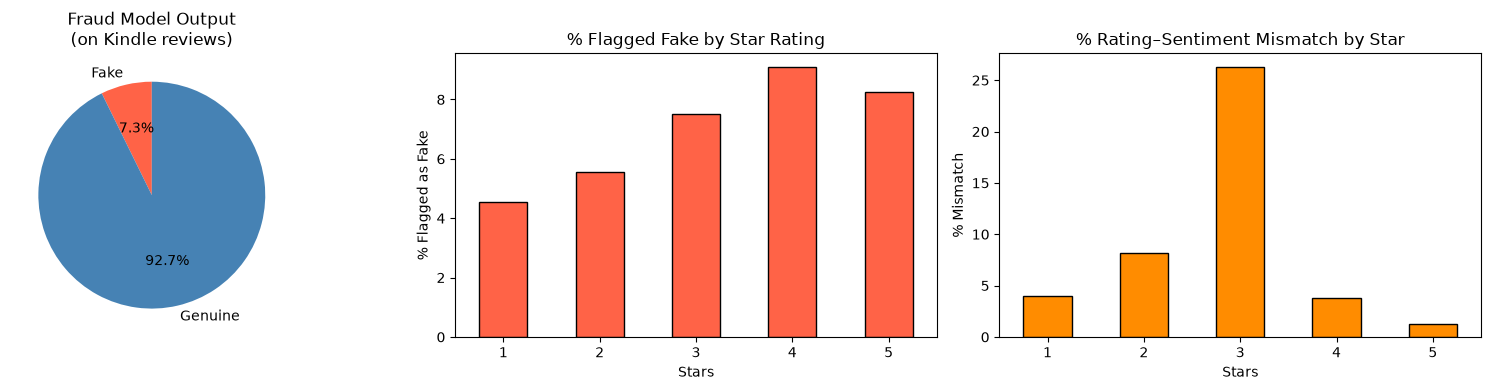


Overall: 873 reviews flagged as fake (7.3%)
Rating–Sentiment mismatches: 921 (7.7%)


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Fake % overall
fake_pct = (audit_df["fraud_label"] == "fake").mean() * 100
axes[0].pie([fake_pct, 100-fake_pct], labels=["Fake", "Genuine"],
            colors=["tomato","steelblue"], autopct="%1.1f%%", startangle=90)
axes[0].set_title("Fraud Model Output\n(on Kindle reviews)")

# Fake % by star rating
fake_by_rating = audit_df.groupby("rating")["fraud_label"].apply(lambda x: (x=="fake").mean()*100)
fake_by_rating.plot(kind="bar", ax=axes[1], color="tomato", edgecolor="black")
axes[1].set_title("% Flagged Fake by Star Rating")
axes[1].set_xlabel("Stars")
axes[1].set_ylabel("% Flagged as Fake")
axes[1].set_xticklabels(fake_by_rating.index, rotation=0)

# Mismatch % by rating
mismatch_by_rating = audit_df.groupby("rating")["mismatch"].mean() * 100
mismatch_by_rating.plot(kind="bar", ax=axes[2], color="darkorange", edgecolor="black")
axes[2].set_title("% Rating–Sentiment Mismatch by Star")
axes[2].set_xlabel("Stars")
axes[2].set_ylabel("% Mismatch")
axes[2].set_xticklabels(mismatch_by_rating.index, rotation=0)

plt.tight_layout()
plt.show()

print(f"\nOverall: {(audit_df['fraud_label']=='fake').sum():,} reviews flagged as fake ({fake_pct:.1f}%)")
print(f"Rating–Sentiment mismatches: {audit_df['mismatch'].sum():,} ({audit_df['mismatch'].mean()*100:.1f}%)")


### 5.2 Top 10 most suspicious reviews

In [19]:
top10 = audit_df.nlargest(10, "fake_prob")[["rating","fake_prob","sentiment","mismatch","reviewText"]]
for i, (_, row) in enumerate(top10.iterrows(), 1):
    flag = " ⚠ RATING MISMATCH" if row["mismatch"] else ""
    print(f"\n[{i}] ★{row['rating']}  fake_prob={row['fake_prob']:.2f}  sentiment={row['sentiment']}{flag}")
    print(f"    {str(row['reviewText'])[:140]}...")



[1] ★3  fake_prob=0.98  sentiment=positive ⚠ RATING MISMATCH
    I really enjoyed this book. The characters were good and the story line was good. I would recommend this book to anyone....

[2] ★5  fake_prob=0.98  sentiment=positive
    This is a great book. I enjoyed the characters and the story line.  It was a good read and didn't require a lot of thought....

[3] ★5  fake_prob=0.98  sentiment=positive
    I have read all the Zane Grey books and they will keep you entertained and give you a feel of the old west. DHD...

[4] ★4  fake_prob=0.97  sentiment=positive
    I really liked this book.  The characters were believable and the story flowed well.  Just wish it was a bit longer....

[5] ★1  fake_prob=0.97  sentiment=negative
    Poorly written, very predictable. No mystery here.  The author herself gave away the plot ending.  The only redeeming quality this story has...

[6] ★4  fake_prob=0.97  sentiment=positive
    I like this. The characters are good. The plot is strong.  I wou

---
## 6. Combined Inference
Use both models together to score any review — this is what the web app will call.

In [20]:
SENT_ID_MAP = {0: "negative", 1: "neutral", 2: "positive"}

def analyze_review(text: str, rating: float = None) -> dict:
    """
    Score a single review with both models.
    Returns fraud label, sentiment, mismatch flag, and a combined suspicion score.
    """
    # Fraud
    fraud_text  = f"{rating} stars. {text}" if rating else text
    fvec        = fraud_tfidf.transform([fraud_text])
    fake_prob   = float(fraud_model.predict_proba(fvec)[0][1])

    # Sentiment
    svec        = sent_tfidf.transform([text])
    sent_pred   = int(sent_model.predict(svec)[0])
    sent_probs  = sent_model.predict_proba(svec)[0]
    sentiment   = SENT_ID_MAP[sent_pred]

    # Mismatch
    mismatch = False
    if rating:
        exp = "negative" if rating <= 2 else ("neutral" if rating == 3 else "positive")
        mismatch = (sentiment != exp)

    # Combined suspicion (fake_prob + 0.15 boost for mismatch)
    suspicion = round(min(1.0, fake_prob + (0.15 if mismatch else 0.0)), 4)

    return {
        "fraud_label"     : "fake" if fake_prob > 0.5 else "genuine",
        "fake_prob"       : round(fake_prob, 4),
        "sentiment"       : sentiment,
        "sentiment_conf"  : round(float(max(sent_probs)), 4),
        "rating_mismatch" : mismatch,
        "suspicion_score" : suspicion,     # 0 = clean, 1 = very suspicious
    }


# ── Test it ──────────────────────────────────────────────────────────────
test_cases = [
    ("This product is okay. Does what it says, nothing special.",         3.0),
    ("Stopped working after 2 days. Very disappointed with quality.",     5.0),  # mismatch!
    ("Absolutely love it, works perfectly, highly recommend to everyone!", 5.0),
    ("Worst purchase ever. Complete waste of money. Do not buy.",         1.0),
    ("Amazing product great product love this product best product ever!", 5.0), # suspicious
]

print(f"{'TEXT':<55} {'FRAUD':<9} {'SENTIMENT':<11} {'MISMATCH':<10} {'SUSPICION'}")
print("─" * 105)
for text, rating in test_cases:
    r = analyze_review(text, rating)
    mm = "⚠ YES" if r["rating_mismatch"] else "no"
    print(f"{text[:54]:<55} {r['fraud_label']:<9} {r['sentiment']:<11} {mm:<10} {r['suspicion_score']:.2f}")


TEXT                                                    FRAUD     SENTIMENT   MISMATCH   SUSPICION
─────────────────────────────────────────────────────────────────────────────────────────────────────────
This product is okay. Does what it says, nothing speci  genuine   neutral     no         0.15
Stopped working after 2 days. Very disappointed with q  genuine   negative    ⚠ YES      0.32
Absolutely love it, works perfectly, highly recommend   genuine   positive    no         0.21
Worst purchase ever. Complete waste of money. Do not b  genuine   negative    no         0.16
Amazing product great product love this product best p  genuine   positive    no         0.23
